# Fig. 3: gene weight inference

EnrichMap (null) scored with predefined, inferred (CV) and unweighted gene weights on signatures of 10 signal and 10 noise
genes, against AUCell, GSVA, ssGSEA, Z score, Scanpy and GSDensity. Panels of the final Fig. 3: a EnrichMap maps, b inferred
weight vs log2FC, c bootstrap agreement, d per-spot agreement, e comparator maps, f Cohen's d.

In [1]:
import os
import warnings

os.environ["PYTHONWARNINGS"] = "ignore"
warnings.filterwarnings("ignore")

In [2]:
import scanpy as sc
import squidpy as sq
import pandas as pd
import numpy as np
import enrichmap as em
import matplotlib.pyplot as plt
import seaborn as sns
import pickle

from scipy.sparse import issparse
from scipy.stats import spearmanr, pearsonr, linregress, mannwhitneyu
from sklearn.metrics import roc_auc_score, average_precision_score, f1_score

In [3]:
sc.set_figure_params(frameon=False, fontsize=6)
sc.settings._vector_friendly = False
plt.rcParams["axes.grid"] = False

In [4]:
# set working directory
# repository root (the folder containing `notebooks/`); safe to re-run this cell
import sys
project_dir = os.getcwd()
if os.path.basename(project_dir) == "notebooks":
    project_dir = os.path.dirname(project_dir)
project_dir += "/"
sys.path.insert(0, project_dir + "notebooks")  # helpers.py and score_signatures.py
working_dir = project_dir
os.chdir(working_dir)

# set figure directory
figure_dir = working_dir + "figures/"
os.makedirs(figure_dir, exist_ok=True)

# processed data directory
processed_data = project_dir + "processed_data/"

# source data directory
source_dir = working_dir + "source_data/"
os.makedirs(source_dir, exist_ok=True)

In [5]:
colours = {
    "EnrichMap (null)": "#2f0bdf",
    "AUCell": "#86bf6e",
    "GSVA": "#c76663",
    "ssGSEA": "#8f6eb0",
    "Z score": "#866342",
    "Scanpy": "#cf83bd",
    "GSDensity": "#e3a33b",
}
spot_size = 20

In [6]:
from helpers import (
    assign_weights,
    cohens_d,
    compute_cv_log2fc_gene_stats,
    bootstrap_spearman,
    set_box_ratio,
)

In [7]:
# 1. Load data and signatures (18_visium_weights cells 5-6)
adata = sc.read_h5ad(processed_data + "visium_brain_adata.h5ad")

cell_type_1 = "Pyramidal_layer"
cell_type_2 = "Striatum"

with open(project_dir + f"{cell_type_1}_signatures.pkl", "rb") as f:
    signature_dict_pyramidal = pickle.load(f)

with open(project_dir + f"{cell_type_2}_signatures.pkl", "rb") as f:
    signature_dict_striatum = pickle.load(f)

signature_1 = signature_dict_pyramidal[f"{cell_type_1}_top10"]
signature_2 = signature_dict_striatum[f"{cell_type_2}_top10"]
signatures = {cell_type_1: list(signature_1), cell_type_2: list(signature_2)}
masks = {ct: (adata.obs["cluster"] == ct).values for ct in signatures}

print(f"{cell_type_1} ({len(signature_1)} genes): {list(signature_1)}")
print(f"{cell_type_2} ({len(signature_2)} genes): {list(signature_2)}")
print({ct: int(m.sum()) for ct, m in masks.items()})

Pyramidal_layer (10 genes): ['Lefty1', '6330420H09Rik', 'B230110G15Rik', 'Fgf16', 'Fibcd1', '4921539H07Rik', 'Spink8', 'Efcab6', 'Tmprss6', 'Gm2115']
Striatum (10 genes): ['Ucn3', 'Cyp19a1', 'Adora2a', 'Ccdc42', 'Ido1', 'Sstr5', 'Chrna10', 'Gm48485', '6430628N08Rik', 'Penk']
{'Pyramidal_layer': 42, 'Striatum': 153}


In [8]:
# 2. Noise genes (18_visium_weights cell 7)
# Compute per-gene mean and CV across all spots
if issparse(adata.X):
    gene_means_arr = np.asarray(adata.X.mean(axis=0)).flatten()
    gene_sq_means  = np.asarray(adata.X.multiply(adata.X).mean(axis=0)).flatten()
    gene_vars_arr  = gene_sq_means - gene_means_arr ** 2
else:
    gene_means_arr = adata.X.mean(axis=0)
    gene_vars_arr  = adata.X.var(axis=0)

gene_mean_series = pd.Series(gene_means_arr, index=adata.var_names)
gene_cv_series   = pd.Series(
    np.where(gene_means_arr > 0,
             np.sqrt(np.maximum(gene_vars_arr, 0)) / gene_means_arr, 0.0),
    index=adata.var_names,
)

all_sig_genes = set(list(signature_1) + list(signature_2))

# --- Noise gene selection principle ---
# CV is exactly the criterion EnrichMap uses to assign weights.
# Noise genes must have CV strictly below the MINIMUM CV of any signal gene,
# guaranteeing that CV inference ranks every signal gene above every noise gene.
# An expression floor (Q25 of expressed background) ensures noise genes actually
# contribute to the raw score, making the raw vs inferred comparison meaningful.

sig_cvs      = gene_cv_series[[g for g in all_sig_genes if g in adata.var_names]]
min_sig_cv   = sig_cvs.min()

bg_expressed = [g for g in adata.var_names
                if g not in all_sig_genes and gene_mean_series[g] > 0]
expr_floor   = gene_mean_series[bg_expressed].quantile(0.25)

noise_candidates = [
    g for g in bg_expressed
    if gene_cv_series[g] < min_sig_cv
    and gene_mean_series[g] >= expr_floor
]

print(f"Signal CVs — min: {min_sig_cv:.3f}, max: {sig_cvs.max():.3f}")
print(f"Expression floor (Q25 of expressed background): {expr_floor:.4f}")
print(f"{len(noise_candidates)} candidates with CV < min(signal CV) and mean ≥ floor")

rng_noise   = np.random.default_rng(seed=42)
noise_genes = sorted(rng_noise.choice(noise_candidates, size=10, replace=False).tolist())

selected_stats = pd.DataFrame({
    "mean": gene_mean_series[noise_genes],
    "CV":   gene_cv_series[noise_genes],
})

Signal CVs — min: 1.529, max: 13.912
Expression floor (Q25 of expressed background): 0.0091
6899 candidates with CV < min(signal CV) and mean ≥ floor


In [9]:
# 3. Predefined (known) weights (18_visium_weights cells 10 and 12)
rng = np.random.default_rng(seed=0)

known_weights_dict = {
    f"{cell_type_1}_known": assign_weights(
        pos_genes=list(signature_1), zero_genes=noise_genes, rng=rng
    ),
    f"{cell_type_2}_known": assign_weights(
        pos_genes=list(signature_2), zero_genes=noise_genes, rng=rng
    ),
}

In [10]:
# 4. EnrichMap (null) with predefined, inferred and unweighted weights (18_visium_weights cells 12-16)
inferred_dict = {
    f"{cell_type_1}_inferred": list(signature_1) + noise_genes,
    f"{cell_type_2}_inferred": list(signature_2) + noise_genes,
}
raw_weights_dict = {
    f"{cell_type_1}_raw": {gene: 1 for gene in list(signature_1) + noise_genes},
    f"{cell_type_2}_raw": {gene: 1 for gene in list(signature_2) + noise_genes},
}

variants = {
    "null": dict(
        null_model=True, correct_spatial_covariates=False, compute_q_vals=True
    ),
}
labels = {"null": "EnrichMap (null)"}
conditions = {
    "known": "Predefined weights",
    "inferred": "Inferred weights",
    "raw": "Unweighted (raw)",
}

for name, kwargs in variants.items():
    em.tl.score(
        adata,
        gene_weights={f"{k}_{name}": w for k, w in known_weights_dict.items()},
        **kwargs,
    )
    em.tl.score(
        adata,
        gene_set={f"{k}_{name}": g for k, g in inferred_dict.items()},
        **kwargs,
    )
    em.tl.score(
        adata,
        gene_weights={f"{k}_{name}": w for k, w in raw_weights_dict.items()},
        **kwargs,
    )


  0%|          | 0/2 [00:00<?, ?it/s]

Scoring Pyramidal_layer_known_null: 20/20 genes found:   0%|          | 0/2 [00:00<?, ?it/s]

Scoring Striatum_known_null: 20/20 genes found:   0%|          | 0/2 [00:00<?, ?it/s]       

Scoring Striatum_known_null: 20/20 genes found: 100%|██████████| 2/2 [00:00<00:00, 383.88it/s]

  0%|          | 0/2 [00:00<?, ?it/s]

Scoring Pyramidal_layer_inferred_null: 20/20 genes found:   0%|          | 0/2 [00:00<?, ?it/s]

... (4 outputs left out)

  0%|          | 0/2 [00:00<?, ?it/s]

Scoring Pyramidal_layer_raw_null: 20/20 genes found:   0%|          | 0/2 [00:00<?, ?it/s]

Scoring Striatum_raw_null: 20/20 genes found:   0%|          | 0/2 [00:00<?, ?it/s]       

Scoring Striatum_raw_null: 20/20 genes found: 100%|██████████| 2/2 [00:00<00:00, 456.92it/s]

In [11]:
# 6. Comparator methods on the same noisy gene sets (18_visium_weights cells 37-38)
from score_signatures import score_signatures

# Same gene sets as conditions B and C
benchmark_sigs = {
    cell_type_1: list(signature_1) + noise_genes,
    cell_type_2: list(signature_2) + noise_genes,
}

adata = score_signatures(
    adata,
    signatures_dict=benchmark_sigs,
    methods=["aucell", "scanpy", "ssgsea", "gsva", "zscore"],
)

In [12]:
# 7. GSDensity relevance (x 10^3; relevance sums to 1 over spots) of the noisy 20-gene sets
for ct in signatures:
    gsd = pd.read_csv(working_dir + f"data/gsd_cache/brain/fig3/{ct}_noisy.csv", index_col=0)
    adata.obs[f"{ct}_noisy_gsdensity_score"] = gsd["relevance"].reindex(adata.obs_names).values * 1e3

# score column of each method on the noisy gene sets (EnrichMap: inferred weights)
method_keys = {
    "EnrichMap (null)": "{ct}_inferred_null_score",
    "AUCell": "{ct}_aucell",
    "GSVA": "{ct}_gsva",
    "ssGSEA": "{ct}_ssgsea",
    "Z score": "{ct}_zscore",
    "Scanpy": "{ct}_scanpy",
    "GSDensity": "{ct}_noisy_gsdensity_score",
}

In [13]:
# 8. Fig. 3f: Cohen's d (18_visium_weights cells 24 and 39) per weighting and method
summary_rows = []
for ct in signatures:
    y = masks[ct]
    entries = [(labels[name], conditions[cond], adata.obs[f"{ct}_{cond}_{name}_score"].values)
               for name in variants for cond in conditions]
    entries += [(m, "unweighted gene set", adata.obs[k.format(ct=ct)].values)
                for m, k in method_keys.items() if not m.startswith("EnrichMap")]
    for method, weights, s in entries:
        s = np.asarray(s, dtype=np.float64)
        summary_rows.append({
            "region": ct,
            "method": method,
            "weights": weights,
            "cohens_d": cohens_d(s[y], s[~y]),
            "AUROC": roc_auc_score(y, s),
            "AUPRC": average_precision_score(y, s),
            "n_target": int(y.sum()),
            "n_rest": int((~y).sum()),
            "mean_target": s[y].mean(),
            "mean_rest": s[~y].mean(),
            "sd_target": s[y].std(ddof=1),
            "sd_rest": s[~y].std(ddof=1),
        })
cd_df = pd.DataFrame(summary_rows)

In [14]:
# 10. Fig. 3b: CV (inferred weight) vs log2FC per gene (18_visium_weights cell 33, with the detection rate)

# the published "Spearman ρ" of panel b is a Pearson r (pandas .corr); both are reported
r_col = "Pearson r, signal genes (published as 'Spearman ρ')"
gene_tabs, summary_rows = [], []
for ct, genes in signatures.items():
    gdf = compute_cv_log2fc_gene_stats(adata, genes, noise_genes, ct, known_weights_dict[f"{ct}_known"])
    tg = gdf[gdf["is_target"]]
    r, p_r = pearsonr(tg["CV"], tg["log2FC"])
    rho, p_rho = spearmanr(tg["CV"], tg["log2FC"])
    gdf.insert(0, "region", ct)
    gene_tabs.append(gdf)
    summary_rows.append({
        "region": ct,
        r_col: r,
        "Pearson p": p_r,
        "Spearman ρ, signal genes": rho,
        "Spearman p": p_rho,
        "Spearman ρ, signal + noise genes": spearmanr(gdf["CV"], gdf["log2FC"]).statistic,
        "n signal genes": len(tg),
    })
gene_df = pd.concat(gene_tabs, ignore_index=True)
b_stats = pd.DataFrame(summary_rows)

In [15]:
# 12. Fig. 3d: per-spot agreement with the reference score (18_visium_weights cell 27)
# EnrichMap: predefined-weight score (x) vs inferred / unweighted score (y)
pairs = []
for name in variants:
    for ct in signatures:
        for cond in ["inferred", "raw"]:
            pairs.append(
                (
                    labels[name],
                    ct,
                    conditions[cond],
                    adata.obs[f"{ct}_known_{name}_score"].values,
                    adata.obs[f"{ct}_{cond}_{name}_score"].values,
                )
            )

summary_rows = []
for method, ct, condition, x, y in pairs:
    slope, intercept, *_ = linregress(x, y)
    rho, p_value = spearmanr(x, y)
    summary_rows.append(
        {
            "method": method,
            "region": ct,
            "condition": condition,
            "reference (x)": "predefined weights",
            "Spearman ρ": rho,
            "Spearman p": p_value,
            "Pearson r": pearsonr(x, y)[0],
            "regression slope": slope,
            "regression intercept": intercept,
            "n spots": len(x),
        }
    )
d_stats = pd.DataFrame(summary_rows)

In [16]:
# 13. Fig. 3c: spot bootstrap of the panel d Spearman ρ (18_visium_weights cell 31)

# same seed for every call, so the resampled spots are shared and inferred - raw is paired
n_boot = 1000
boot_records, summary_rows = [], []
for name in variants:
    for ct in signatures:
        x = adata.obs[f"{ct}_known_{name}_score"].values
        boots = {
            cond: bootstrap_spearman(
                x, adata.obs[f"{ct}_{cond}_{name}_score"].values, n_boot=n_boot
            )
            for cond in ["inferred", "raw"]
        }
        delta = boots["inferred"] - boots["raw"]
        u, p = mannwhitneyu(boots["inferred"], boots["raw"], alternative="two-sided")
        for cond, label in [("inferred", "Inferred"), ("raw", "Raw")]:
            v = boots[cond]
            boot_records.append(
                pd.DataFrame(
                    {
                        "method": labels[name],
                        "region": ct,
                        "condition": label,
                        "reference": "predefined weights",
                        "bootstrap replicate": np.arange(n_boot),
                        "Spearman ρ": v,
                    }
                )
            )
            summary_rows.append(
                {
                    "method": labels[name],
                    "region": ct,
                    "condition": label,
                    "n": len(v),
                    "median": np.median(v),
                    "Q1": np.percentile(v, 25),
                    "Q3": np.percentile(v, 75),
                    "min": v.min(),
                    "max": v.max(),
                    "Δρ inferred - raw (paired), median": np.median(delta),
                    "Δρ 95% CI low": np.percentile(delta, 2.5),
                    "Δρ 95% CI high": np.percentile(delta, 97.5),
                    "fraction of resamples with inferred > raw": np.mean(delta > 0),
                    "Mann-Whitney U (inferred vs raw)": u,
                    "Mann-Whitney p (two-sided)": p,
                }
            )
boot_df = pd.concat(boot_records, ignore_index=True)
c_stats = pd.DataFrame(summary_rows)
cols = [
    "median",
    "Q1",
    "Q3",
    "Δρ inferred - raw (paired), median",
    "Δρ 95% CI low",
    "Δρ 95% CI high",
]

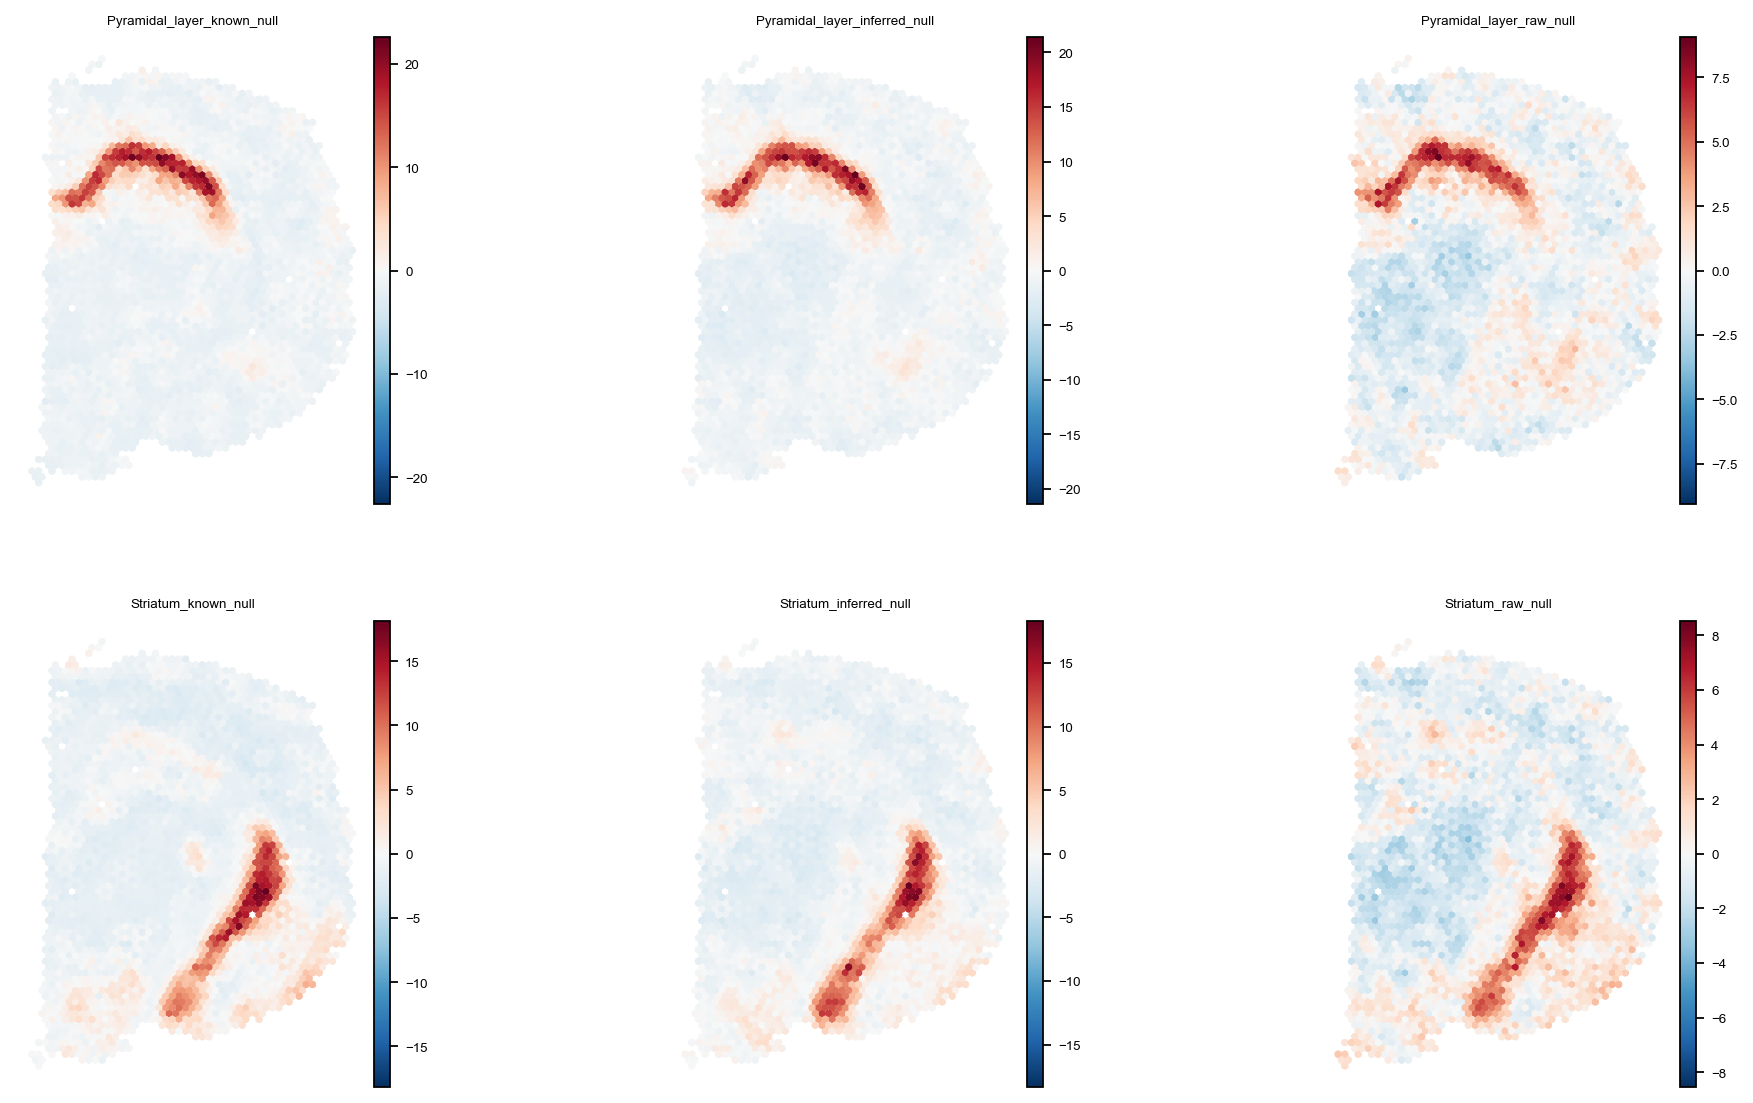

In [17]:
# 16. Fig. 3a: EnrichMap (null) with predefined, inferred and unweighted weights, centred at 0
coords = adata.obsm["spatial"]
keys = [f"{ct}_{cond}_null_score" for ct in signatures for cond in conditions]
em.pl.spatial_enrichmap(
    adata,
    score_key=keys,
    shape=None,
    size=spot_size,
    vcenter=0,
    ncols=3,
    save="Fig3a_score_maps.pdf",
)
maps = adata.obs[keys].copy()
maps.insert(0, "y", coords[:, 1])
maps.insert(0, "x", coords[:, 0])
maps.to_csv(source_dir + "Fig3a_score_maps.csv")

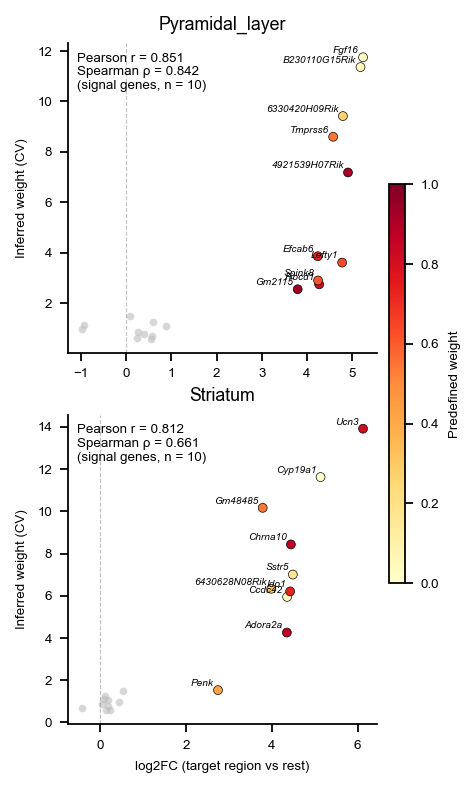

In [18]:
# 17. Fig. 3b: inferred weight (CV) vs log2FC, labelled Pearson r (published as Spearman ρ) and Spearman ρ
fig, axes = plt.subplots(2, 1, figsize=(3.2, 5.6))
for ax, ct in zip(axes, signatures):
    gdf = gene_df[gene_df["region"] == ct]
    noise, sig = gdf[~gdf["is_target"]], gdf[gdf["is_target"]]
    ax.scatter(noise["log2FC"], noise["CV"], c="#BDBDBD", s=12, alpha=0.6, linewidths=0, zorder=2)
    pts = ax.scatter(sig["log2FC"], sig["CV"], c=sig["known_weight"], cmap="YlOrRd", vmin=0, vmax=1,
                     s=16, edgecolors="black", linewidths=0.3, zorder=3)
    for _, r in sig.iterrows():
        ax.annotate(r["gene"], (r["log2FC"], r["CV"]), fontsize=4.5, style="italic",
                    ha="right", va="bottom", xytext=(-2, 1), textcoords="offset points")
    st = b_stats[b_stats["region"] == ct].iloc[0]
    ax.text(0.03, 0.97, f"Pearson r = {st[r_col]:.3f}\nSpearman ρ = {st['Spearman ρ, signal genes']:.3f}\n"
            "(signal genes, n = 10)", transform=ax.transAxes, va="top", fontsize=6)
    ax.axvline(0, color="grey", linestyle="--", linewidth=0.5, alpha=0.5)
    ax.set_ylabel("Inferred weight (CV)")
    ax.set_title(ct, fontsize=8)
    ax.grid(False)
    ax.set_box_aspect(1)
    sns.despine(ax=ax)
    
axes[1].set_xlabel("log2FC (target region vs rest)")
cb = fig.colorbar(pts, ax=axes, fraction=0.04, pad=0.03, aspect=25)
cb.set_label("Predefined weight", fontsize=6)
plt.savefig(figure_dir + "Fig3b_cv_vs_log2fc.pdf", bbox_inches="tight")
plt.show()
gene_df.to_csv(source_dir + "Fig3b_cv_vs_log2fc.csv", index=False)

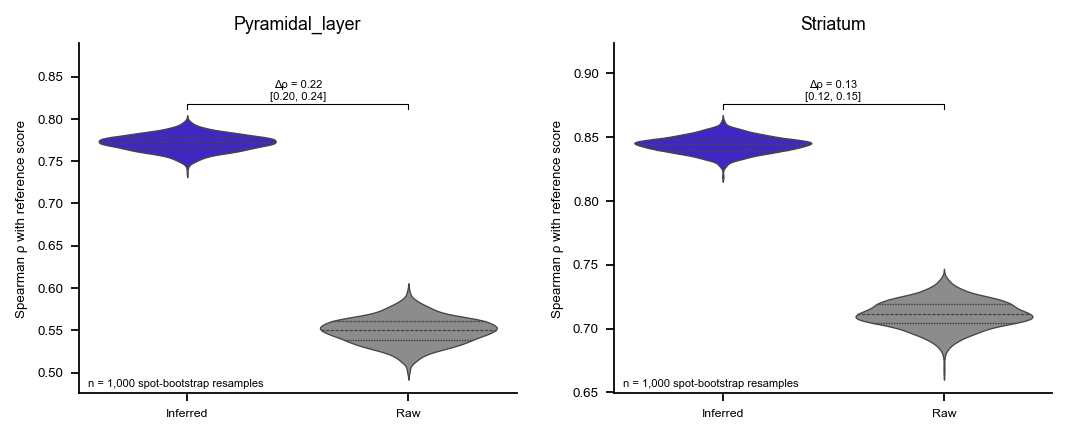

In [19]:
# 19. Fig. 3c: bootstrap distribution of ρ with the reference score, per variant
slots = [(labels[name], cond) for name in variants for cond in ["Inferred", "Raw"]]
fig, axes = plt.subplots(1, 2, figsize=(7.0, 2.7))
for ax, ct in zip(axes, signatures):
    sub = boot_df[boot_df["region"] == ct].copy()
    sub["slot"] = sub["method"] + " | " + sub["condition"]
    order = [f"{m} | {c}" for m, c in slots]
    sns.violinplot(data=sub, x="slot", y="Spearman ρ", hue="slot", order=order, hue_order=order,
                   palette={f"{m} | {c}": {"Inferred": colours[m], "Raw": "#8c8c8c"}[c] for m, c in slots}, inner="quart", linewidth=0.6,
                   legend=False, ax=ax)
    top = sub["Spearman ρ"].max()
    span = top - sub["Spearman ρ"].min()
    for i, name in enumerate(variants):
        st = c_stats[(c_stats["method"] == labels[name]) & (c_stats["region"] == ct)].iloc[0]
        y = top + 0.06 * span
        ax.plot([2 * i, 2 * i, 2 * i + 1, 2 * i + 1], [y - 0.02 * span, y, y, y - 0.02 * span],
                color="black", linewidth=0.5)
        ax.text(2 * i + 0.5, y + 0.01 * span,
                f"Δρ = {st['Δρ inferred - raw (paired), median']:.2f}\n"
                f"[{st['Δρ 95% CI low']:.2f}, {st['Δρ 95% CI high']:.2f}]",
                ha="center", va="bottom", fontsize=5)
    ax.set_xticks(range(len(order)))
    ax.set_xticklabels(["Inferred", "Raw"] * len(variants), fontsize=5.5)
    ax.set_ylim(None, top + 0.3 * span)
    ax.set_xlabel("")
    ax.set_ylabel("Spearman ρ with reference score")
    ax.set_title(ct, fontsize=8)
    ax.text(0.02, 0.02, f"n = {n_boot:,} spot-bootstrap resamples", transform=ax.transAxes, fontsize=5)
    ax.grid(False)
    ax.set_box_aspect(1)
    sns.despine(ax=ax)
plt.tight_layout()
set_box_ratio(fig)
plt.savefig(figure_dir + "Fig3c_bootstrap_agreement.pdf", bbox_inches="tight")
plt.show()
boot_df.to_csv(source_dir + "Fig3c_bootstrap_agreement.csv", index=False)

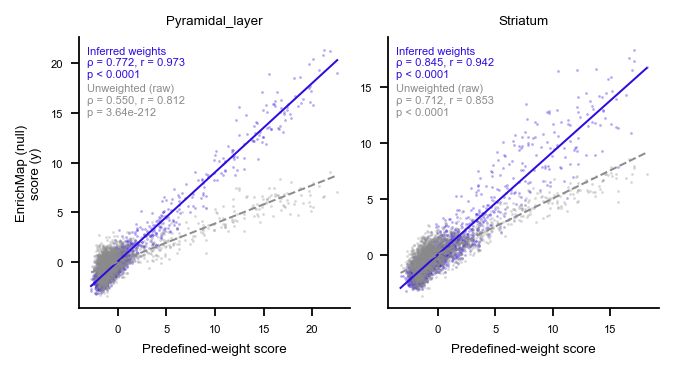

In [20]:
# 20. Fig. 3d: per-spot reference score vs inferred-weight and unweighted scores

rows = ["EnrichMap (null)"]
columns = list(signatures)

cond_colours = {
    "inferred": colours["EnrichMap (null)"],
    "raw": "#8c8c8c",
}

fig, axes = plt.subplots(
    1,
    len(columns),
    figsize=(4.2, 2.8),
    squeeze=False,
)

for j, ct in enumerate(columns):
    ax = axes[0, j]

    for method in rows:
        name = {v: k for k, v in labels.items()}[method]

        x = adata.obs[f"{ct}_known_{name}_score"].values

        for cond in ["inferred", "raw"]:
            y = adata.obs[f"{ct}_{cond}_{name}_score"].values

            st = d_stats[
                (d_stats["method"] == method)
                & (d_stats["region"] == ct)
                & (d_stats["condition"] == conditions[cond])
            ].iloc[0]

            color = cond_colours[cond]

            ax.scatter(
                x,
                y,
                s=1.5,
                alpha=0.35,
                linewidths=0,
                color=color,
                marker="o",
                label=conditions[cond],
            )

            xr = np.linspace(x.min(), x.max(), 50)

            ax.plot(
                xr,
                st["regression slope"] * xr + st["regression intercept"],
                color=color,
                linewidth=0.9,
                linestyle="-" if cond == "inferred" else "--",
            )

            p_text = (
                "p < 0.0001"
                if st["Spearman p"] < 1e-300
                else f"p = {st['Spearman p']:.2e}"
            )

            # Separate annotations for inferred and raw
            ax.text(
                0.03,
                0.97 if cond == "inferred" else 0.83,
                (
                    f"{conditions[cond]}\n"
                    f"ρ = {st['Spearman ρ']:.3f}, "
                    f"r = {st['Pearson r']:.3f}\n"
                    f"{p_text}"
                ),
                transform=ax.transAxes,
                va="top",
                fontsize=5,
                color=color,
            )

    ax.set_title(ct, fontsize=6)

    ax.set_xlabel("Predefined-weight score", fontsize=6)

    if j == 0:
        ax.set_ylabel("EnrichMap (null)\nscore (y)", fontsize=6)

    ax.tick_params(labelsize=5)
    ax.grid(False)
    sns.despine(ax=ax)

plt.tight_layout(w_pad=0.8)

set_box_ratio(fig, ratio=1)

plt.savefig(
    figure_dir + "Fig3d_per_spot_agreement.pdf",
    bbox_inches="tight",
)

plt.show()


# Export source data for Fig. 3d (unchanged)

panel_d = []

for ct in signatures:
    tab = pd.DataFrame(
        {
            "spot_id": adata.obs_names,
            "region": ct,
        }
    )

    for name in variants:
        for cond, lab in [
            ("known", "predefined-weight score (x)"),
            ("inferred", "inferred-weight score (y)"),
            ("raw", "unweighted (raw) score (y)"),
        ]:
            tab[f"{labels[name]}: {lab}"] = adata.obs[
                f"{ct}_{cond}_{name}_score"
            ].values

    panel_d.append(tab)

pd.concat(panel_d).to_csv(
    source_dir + "Fig3d_per_spot_agreement.csv",
    index=False,
)

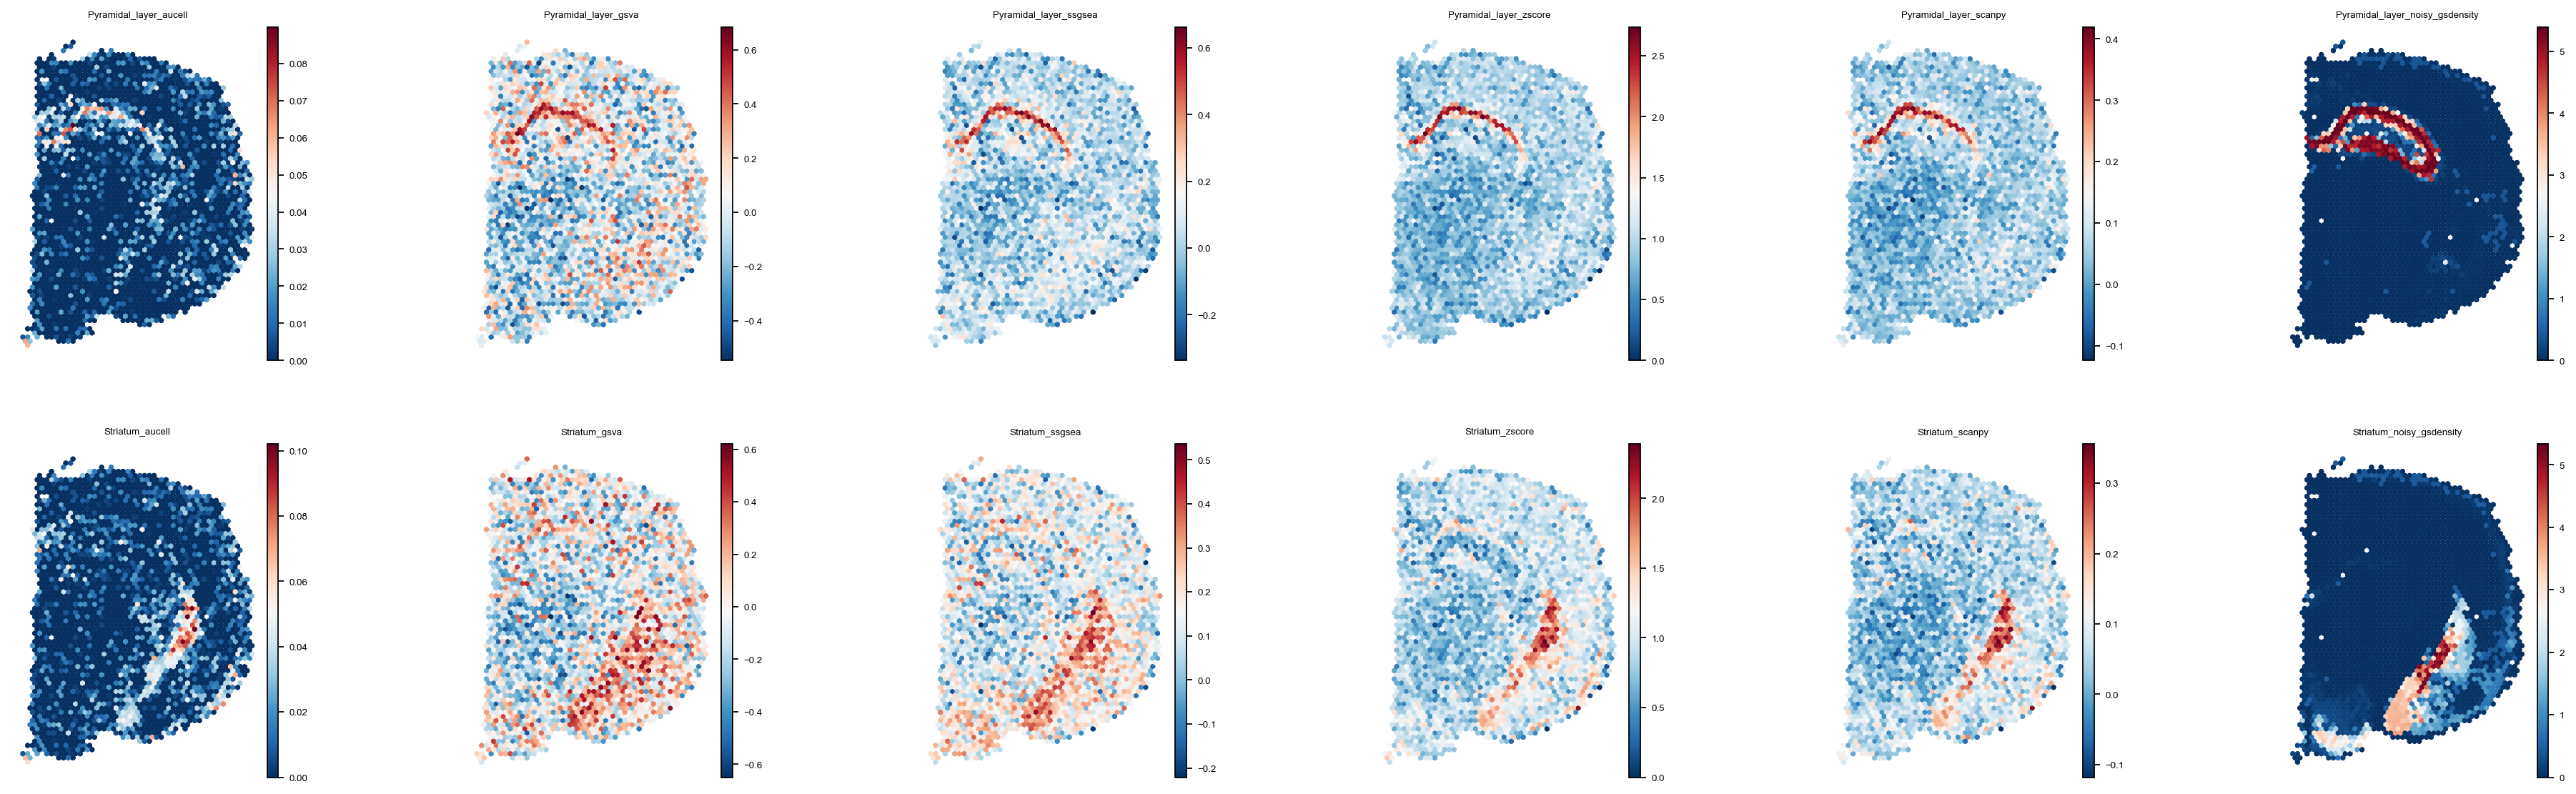

In [21]:
# 21. Fig. 3e: the noisy signatures with the comparators and GSDensity, from minimum to maximum
keys = [k.format(ct=ct) for ct in signatures for m, k in method_keys.items() if not m.startswith("EnrichMap")]
em.pl.spatial_enrichmap(
    adata,
    score_key=keys,
    shape=None,
    size=spot_size,
    vcenter=None,
    ncols=6,
    save="Fig3e_method_maps.pdf",
)
maps = adata.obs[keys].copy()
maps.insert(0, "y", coords[:, 1])
maps.insert(0, "x", coords[:, 0])
maps.to_csv(source_dir + "Fig3e_method_maps.csv")

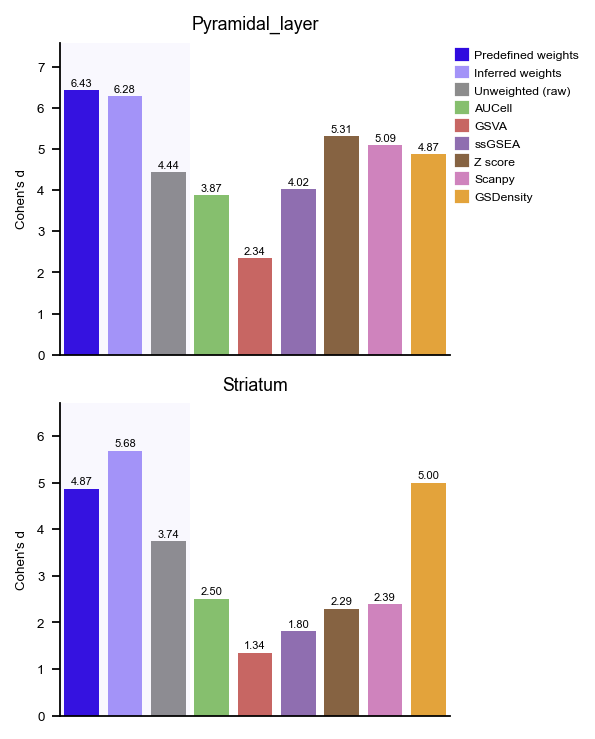

In [22]:
# 22. Fig. 3f: Cohen's d per region; EnrichMap (null) by weighting, then the comparators and GSDensity
weight_colours = dict(zip(conditions.values(), ["#2f0bdf", "#a393f8", "#8c8c8c"]))
groups = [*conditions.values()] + [m for m in method_keys if not m.startswith("EnrichMap")]
fig, axes = plt.subplots(2, 1, figsize=(4.4, 4.6))
for ax, ct in zip(axes, signatures):
    sub = cd_df[cd_df["region"] == ct]
    for g, group in enumerate(groups):
        row = sub[sub["weights"] == group] if group in conditions.values() else sub[sub["method"] == group]
        d = float(row["cohens_d"].iloc[0])
        ax.bar(g, d, width=0.8, color=weight_colours.get(group, colours.get(group)), edgecolor="none")
        ax.text(g, d + 0.05, f"{d:.2f}", ha="center", va="bottom", fontsize=5)
    ax.axvspan(-0.5, len(conditions) - 0.5, color="#a393f8", alpha=0.06, linewidth=0)
    ax.set_xticks([])
    ax.set_xlim(-0.5, len(groups) - 0.5)
    ax.set_ylim(0, sub["cohens_d"].max() * 1.18)
    ax.set_ylabel("Cohen's d")
    ax.set_title(ct, fontsize=8)
    ax.grid(False)
    sns.despine(ax=ax)
handles = [plt.Rectangle((0, 0), 1, 1, color=weight_colours.get(g, colours.get(g))) for g in groups]
axes[0].legend(handles, groups, frameon=False, fontsize=5.5, loc="upper left", bbox_to_anchor=(1.0, 1.0))
plt.tight_layout()
set_box_ratio(fig)
plt.savefig(figure_dir + "Fig3f_cohens_d.pdf", bbox_inches="tight")
plt.show()
cd_df.to_csv(source_dir + "Fig3f_cohens_d.csv", index=False)

In [23]:
# 24. Statistics printed on panels b, c and d
b_stats.to_csv(source_dir + "Fig3b_correlation.csv", index=False)
c_stats.to_csv(source_dir + "Fig3c_bootstrap_summary.csv", index=False)
d_stats.to_csv(source_dir + "Fig3d_agreement.csv", index=False)